CELL 1: Setup Packages, Java 21, & Auto-Restart Kernel


In [ ]:
# ==============================================================================
# CELL 1: SETUP JAVA 21, BITSANDBYTES, PILLOW & AUTO-RESTART
# Configuration: Qwen-2.5-7B + E5-Large-V2
# ==============================================================================
import os

print("======================================================================")
print(" 1. INSTALLING JAVA 21, BITSANDBYTES & RAG PACKAGES")
print("======================================================================")
!apt-get update -q
!apt-get install -y openjdk-21-jdk -q
!update-java-alternatives --set java-1.21.0-openjdk-amd64
!pip install --upgrade --force-reinstall pillow -q
!pip install --upgrade pyserini faiss-gpu sentence-transformers datasets accelerate bitsandbytes -q

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"
os.environ["JVM_PATH"] = "/usr/lib/jvm/java-21-openjdk-amd64/lib/server/libjvm.so"

from google.colab import drive
print("\n======================================================================")
print(" 2. MOUNTING GOOGLE DRIVE")
print("======================================================================")
drive.mount('/content/drive', force_remount=True)

print("\n======================================================================")
print(" ✅ SETUP COMPLETE! RESTARTING KERNEL NOW FOR CLEAN MEMORY START...")
print("======================================================================")

# Automatically restarts Colab kernel cleanly
os._exit(0)

 1. INSTALLING JAVA 21, BITSANDBYTES & RAG PACKAGES
Hit:1 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:2 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:3 https://cli.github.com/packages stable InRelease
Hit:4 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:5 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Hit:6 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:7 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:9 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:10 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Hit:11 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Reading package lists...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide i

In [1]:
# ==============================================================================
# CELL 2: LOAD SUBSTRATES (QWEN-2.5-7B + E5-LARGE-V2) & EXECUTE PROPOSAL PIPELINE
# Alignment: Chapter 3, Table 3.2 & Section 3.2.1
# ==============================================================================
import os
import glob
import json
import time
import torch
import faiss
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm
from google.colab import drive
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModel, BitsAndBytesConfig
from datasets import load_dataset

# 1. Environment & Java 21 Setup
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"
os.environ["JVM_PATH"] = "/usr/lib/jvm/java-21-openjdk-amd64/lib/server/libjvm.so"

drive.mount('/content/drive', force_remount=True)
from pyserini.search.lucene import LuceneSearcher

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[INFO] Active Hardware Accelerator: {device.upper()}")

# 2. Paths
BASE_DIR = '/content/drive/My Drive/Objective 1'
BM25_DIR = os.path.join(BASE_DIR, 'indices', 'bm25')
FAISS_E5_DIR = os.path.join(BASE_DIR, 'indices', 'faiss_shards') # E5 Vector Shards
POLICY_MODEL_PATH = os.path.join(BASE_DIR, 'laro_supervision', 'laro_4class_policy_controller.pt')

bm25_searcher = LuceneSearcher(BM25_DIR)
print(f"✅ [SUBSTRATE 1/2] Lucene BM25 Loaded ({bm25_searcher.num_docs:,} docs)")

# Multi-Shard E5 FAISS Engine
class FullE5FAISSSearcher:
    def __init__(self, shards_dir):
        self.shards = []
        self.id_maps = []
        index_files = sorted([f for f in os.listdir(shards_dir) if f.endswith('.index')])
        for idx_f in index_files:
            prefix = idx_f.replace('.index', '').replace('kilt_e5_shard_', '')
            map_f = f"faiss_map_shard_{prefix}.json"
            idx_path = os.path.join(shards_dir, idx_f)
            map_path = os.path.join(shards_dir, map_f)
            index = faiss.read_index(idx_path)
            with open(map_path, 'r', encoding='utf-8') as f:
                id_map = json.load(f)
            self.shards.append(index)
            self.id_maps.append(id_map)
        print(f"✅ [SUBSTRATE 2/2] FAISS E5 Dense Active ({len(self.shards)} shards, 21.11M passages)")

    def search(self, query_vector, top_k=5):
        all_candidates = []
        for index, id_map in zip(self.shards, self.id_maps):
            scores, indices = index.search(query_vector, top_k)
            for score, idx in zip(scores[0], indices[0]):
                if idx != -1:
                    cid = id_map.get(str(idx), f"idx_{idx}")
                    all_candidates.append((float(score), cid))
        all_candidates.sort(key=lambda x: x[0], reverse=True)
        return all_candidates[:top_k]

e5_faiss_searcher = FullE5FAISSSearcher(FAISS_E5_DIR)

# 3. Load E5 Query Encoder
E5_MODEL_NAME = "intfloat/e5-large-v2"
e5_tokenizer = AutoTokenizer.from_pretrained(E5_MODEL_NAME, use_fast=True)
e5_model = AutoModel.from_pretrained(E5_MODEL_NAME).to(device)
e5_model.eval()

query_encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)

# 4. Load Qwen-2.5-7B Generator Backbone (4-bit NF4)
LLM_BACKBONE = "Qwen/Qwen2.5-7B-Instruct"
print(f"\n[INFO] Loading Qwen-2.5-7B Generator Backbone ({LLM_BACKBONE})...")

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

llm_tokenizer = AutoTokenizer.from_pretrained(LLM_BACKBONE)
llm_model = AutoModelForCausalLM.from_pretrained(
    LLM_BACKBONE,
    quantization_config=bnb_config,
    device_map="auto"
)
llm_model.eval()

# 5. Load LARO Policy Controller
class LARO4ClassPolicyMLP(nn.Module):
    def __init__(self, input_dim, num_classes=4):
        super(LARO4ClassPolicyMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256), nn.LayerNorm(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.LayerNorm(128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.network(x)

checkpoint = torch.load(POLICY_MODEL_PATH, map_location=device, weights_only=False)
input_dim = checkpoint['input_dim']
scaler = checkpoint['scaler']
label_map = checkpoint['label_map']
inv_label_map = {v: k for k, v in label_map.items()}

policy_net = LARO4ClassPolicyMLP(input_dim=input_dim, num_classes=4).to(device)
policy_net.load_state_dict(checkpoint['model_state_dict'])
policy_net.eval()

print("✅ E5 Substrate, Qwen-2.5-7B Backbone & LARO Controller Ready!")

# ------------------------------------------------------------------------------
# 6. PIPELINE FUNCTIONS FOR E5 + QWEN-2.5
# ------------------------------------------------------------------------------
def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output[0]
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    return torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)

def encode_dense_query_e5(q_text):
    """E5 Query Encoding requires 'query: ' prefix."""
    formatted_q = f"query: {q_text}"
    enc = e5_tokenizer([formatted_q], padding=True, truncation=True, max_length=256, return_tensors='pt').to(device)
    with torch.no_grad(), torch.amp.autocast('cuda'):
        out = e5_model(**enc)
        emb = mean_pooling(out, enc['attention_mask'])
        emb = F.normalize(emb, p=2, dim=1)
    return emb.cpu().numpy().astype('float32')

def extract_causal_epistemic_signals(query_text):
    messages = [{"role": "user", "content": query_text}]
    prompt = llm_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = llm_tokenizer([prompt], return_tensors="pt").to(device)

    with torch.no_grad():
        outputs = llm_model(**inputs)
        logits = outputs.logits.float()

    input_ids = inputs["input_ids"]
    if input_ids.shape[1] > 1:
        shift_logits = logits[..., :-1, :].contiguous()
        shift_labels = input_ids[..., 1:].contiguous()
        loss_fct = torch.nn.CrossEntropyLoss()
        loss = loss_fct(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1))
        perplexity = torch.exp(loss).item() if not torch.isnan(loss) else 50.0
    else:
        perplexity = 50.0

    probs = F.softmax(logits, dim=-1)
    top2_probs, _ = torch.topk(probs, k=2, dim=-1)
    margin = (top2_probs[0, :, 0] - top2_probs[0, :, 1]).mean().item()

    log_probs = F.log_softmax(logits, dim=-1)
    target_log_probs = log_probs[0, range(input_ids.shape[1]-1), input_ids[0, 1:]] if input_ids.shape[1] > 1 else log_probs[0, 0, 0]
    dispersion = torch.std(target_log_probs).item() if target_log_probs.numel() > 1 else 0.0

    return {
        "sigma_ppl": round(perplexity, 4),
        "sigma_attn_entropy": 1.05,
        "log_prob_dispersion": round(dispersion, 4),
        "top_margin": round(margin, 4)
    }

def is_query_suboptimal(query_text, signals):
    words = query_text.strip().split()
    pronouns = ['it', 'they', 'them', 'this', 'that', 'he', 'she']
    contains_pronoun = any(p in query_text.lower().split() for p in pronouns)
    is_vague = len(words) < 5 and signals['sigma_ppl'] > 50.0
    return contains_pronoun or is_vague

def rewrite_query_llm(query_text):
    messages = [
        {"role": "system", "content": "You are a search query reformulator. Rewrite the query to be explicit, entity-rich, and clear for Wikipedia search. Output ONLY the rewritten query."},
        {"role": "user", "content": f"Query: {query_text}"}
    ]
    prompt = llm_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = llm_tokenizer([prompt], return_tensors="pt").to(device)

    with torch.no_grad():
        out = llm_model.generate(
            inputs.input_ids,
            attention_mask=inputs.attention_mask,
            max_new_tokens=30,
            do_sample=False,
            pad_token_id=llm_tokenizer.eos_token_id
        )
        gen = [output_ids[len(input_ids):] for input_ids, output_ids in zip(inputs.input_ids, out)]
        return llm_tokenizer.batch_decode(gen, skip_special_tokens=True)[0].strip()

def predict_dynamic_granularity_k(action_name, signals, query_text):
    if action_name == "SKIP": return 0, "k=0 (Parametric Fast Path)"
    elif signals['sigma_ppl'] > 200.0 or len(query_text.split()) > 10: return 10, "k=10 (Broad Multi-Hop Depth)"
    elif signals['sigma_ppl'] < 60.0: return 1, "k=1 (Fine-Grained Depth)"
    else: return 5, "k=5 (Standard Depth)"

def execute_qwen_e5_pipeline(query_text, ppl_threshold=80.0, margin_threshold=0.55):
    t_start = time.time()
    signals = extract_causal_epistemic_signals(query_text)
    is_low_uncertainty = (signals['sigma_ppl'] <= ppl_threshold) and (signals['top_margin'] >= margin_threshold)

    if is_low_uncertainty:
        pipeline_tier = "TIER 1 FAST PATH (Phase 1: Direct Generation)"
        action_executed = "SKIP"
        granularity_k, k_label = 0, "k=0 (Parametric Fast Path)"
        search_query = query_text
        retrieved_passages = []
    else:
        pipeline_tier = "TIER 2 DEEP RESEARCH PATH (Phase 2: LARO Control Layer)"
        q_emb = query_encoder.encode([query_text], convert_to_numpy=True)
        cues_arr = np.array([[signals['sigma_ppl'], signals['sigma_attn_entropy'], signals['log_prob_dispersion'], signals['top_margin']]])
        cues_scaled = scaler.transform(cues_arr)
        x_input = torch.tensor(np.hstack([q_emb, cues_scaled]), dtype=torch.float32).to(device)

        with torch.no_grad():
            logits = policy_net(x_input)
            probs = F.softmax(logits, dim=1).cpu().numpy()[0]
            pred_action_id = int(torch.argmax(logits, dim=1).item())

        action_name = inv_label_map[pred_action_id]
        needs_rewrite = is_query_suboptimal(query_text, signals)

        if needs_rewrite or action_name == "REWRITE_RETRIEVE":
            action_executed = "REWRITE_RETRIEVE"
            search_query = rewrite_query_llm(query_text)
        else:
            search_query = query_text
            action_executed = action_name
            if signals['sigma_ppl'] > 25.0 and action_executed == "SKIP":
                action_executed = "SEMANTIC_DENSE"

        granularity_k, k_label = predict_dynamic_granularity_k(action_executed, signals, query_text)
        retrieved_passages = []

        if granularity_k > 0:
            if action_executed == "LEXICAL_BM25":
                hits = bm25_searcher.search(search_query, k=granularity_k)
                for h in hits:
                    d = bm25_searcher.doc(h.docid)
                    if d:
                        try: retrieved_passages.append(json.loads(d.raw()).get("contents", d.contents()))
                        except: retrieved_passages.append(d.contents())
            elif action_executed in ["SEMANTIC_DENSE", "REWRITE_RETRIEVE"]:
                q_vec = encode_dense_query_e5(search_query) # E5 Query Vector
                top_matches = e5_faiss_searcher.search(q_vec, top_k=granularity_k)
                for score, cid in top_matches:
                    doc_obj = bm25_searcher.doc(cid)
                    if doc_obj:
                        try: retrieved_passages.append(json.loads(doc_obj.raw()).get("contents", doc_obj.contents()))
                        except: retrieved_passages.append(doc_obj.contents())

    if retrieved_passages:
        clean_context = "\n\n".join([f"Document {i+1}: {str(p).strip()}" for i, p in enumerate(retrieved_passages)])[:max(granularity_k*500, 500)]
        messages = [
            {"role": "system", "content": "You are a precise AI assistant. Answer directly and concisely based ONLY on the provided documents. If the exact answer is not provided, state that clearly."},
            {"role": "user", "content": f"Documents:\n{clean_context}\n\nQuestion: {query_text}"}
        ]
    else:
        messages = [
            {"role": "system", "content": "You are a precise, factual AI assistant. Answer concisely."},
            {"role": "user", "content": query_text}
        ]

    prompt_text = llm_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    model_inputs = llm_tokenizer([prompt_text], return_tensors="pt").to(device)

    with torch.no_grad():
        generated_ids = llm_model.generate(
            model_inputs.input_ids,
            attention_mask=model_inputs.attention_mask,
            max_new_tokens=80,
            do_sample=False,
            pad_token_id=llm_tokenizer.eos_token_id
        )
        generated_ids = [output_ids[len(input_ids):] for input_ids, output_ids in zip(model_inputs.input_ids, generated_ids)]
        response = llm_tokenizer.batch_decode(generated_ids, skip_special_tokens=True)[0].strip()

    elapsed = round(time.time() - t_start, 2)

    print("\n" + "="*85)
    print(f" RAW USER QUERY: \"{query_text}\"")
    print("="*85)
    print(f"Pipeline Route      : {pipeline_tier}")
    print(f"Action Executed     : [{action_executed}]")
    print(f"Granularity Control : {k_label} (Fetched {len(retrieved_passages)} docs)")
    print(f"Search Query Used   : \"{search_query}\"")
    print(f"\n✨ QWEN-2.5-7B + E5 GROUNDED ANSWER (Latency: {elapsed}s):\n{response}")

# ------------------------------------------------------------------------------
# TEST THE QWEN-2.5 + E5 PIPELINE
# ------------------------------------------------------------------------------
execute_qwen_e5_pipeline("When was Universiti Teknologi Malaysia founded?")
execute_qwen_e5_pipeline("Who directed the movie Inception in 2010?")
execute_qwen_e5_pipeline("who directed it in 2010?")

Mounted at /content/drive
[INFO] Active Hardware Accelerator: CUDA
✅ [SUBSTRATE 1/2] Lucene BM25 Loaded (21,113,601 docs)
✅ [SUBSTRATE 2/2] FAISS E5 Dense Active (6 shards, 21.11M passages)


config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/314 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

✅ E5 Substrate, Qwen-2.5-7B Backbone & LARO Controller Ready!

 RAW USER QUERY: "When was Universiti Teknologi Malaysia founded?"
Pipeline Route      : TIER 2 DEEP RESEARCH PATH (Phase 2: LARO Control Layer)
Action Executed     : [SEMANTIC_DENSE]
Granularity Control : k=5 (Standard Depth) (Fetched 5 docs)
Search Query Used   : "When was Universiti Teknologi Malaysia founded?"

✨ QWEN-2.5-7B + E5 GROUNDED ANSWER (Latency: 14.77s):
The founding date for Universiti Teknologi Malaysia (UTM) is not explicitly stated in the provided documents. The documents discuss the history of related institutions but do not provide a specific founding date for UTM itself.

 RAW USER QUERY: "Who directed the movie Inception in 2010?"
Pipeline Route      : TIER 1 FAST PATH (Phase 1: Direct Generation)
Action Executed     : [SKIP]
Granularity Control : k=0 (Parametric Fast Path) (Fetched 0 docs)
Search Query Used   : "Who directed the movie Inception in 2010?"

✨ QWEN-2.5-7B + E5 GROUNDED ANSWER (Latency: 1

In [2]:
# ==============================================================================
# USER TEST SUITE: 4 NEW QUERIES (QWEN-2.5-7B + E5 SUBSTRATE)
# ==============================================================================

user_custom_queries = [
    # 1. Fashion History / Crime Factoid
    "Why did the founder of Versus die?",

    # 2. Physical Common-Sense Reasoning
    "Would a pear sink in water?",

    # 3. Sports Stadium Geography
    "Where do the Philadelphia Eagles play their home games?",

    # 4. Open-Ended Concept Summary
    "Write summay about LLM?"
]

print("======================================================================")
print(" EXECUTING 4-QUERY TEST SUITE (QWEN-2.5-7B + E5 DENSE RETRIEVER)")
print("======================================================================")

for idx, q_text in enumerate(user_custom_queries, start=1):
    print(f"\n[{idx}/4] PROCESSING QUERY: \"{q_text}\"")
    execute_qwen_e5_pipeline(q_text)
    print("\n" + "#"*85)

 EXECUTING 4-QUERY TEST SUITE (QWEN-2.5-7B + E5 DENSE RETRIEVER)

[1/4] PROCESSING QUERY: "Why did the founder of Versus die?"

 RAW USER QUERY: "Why did the founder of Versus die?"
Pipeline Route      : TIER 2 DEEP RESEARCH PATH (Phase 2: LARO Control Layer)
Action Executed     : [SEMANTIC_DENSE]
Granularity Control : k=10 (Broad Multi-Hop Depth) (Fetched 10 docs)
Search Query Used   : "Why did the founder of Versus die?"

✨ QWEN-2.5-7B + E5 GROUNDED ANSWER (Latency: 16.59s):
The document does not provide information about the founder of Versus dying or who the founder is. The term "Versus" is used in multiple contexts in the provided documents (fashion, arthritis charity, video game, etc.), but no single individual is identified as the founder across all instances. Therefore, based on the given documents, there is insufficient information to answer why the founder of Versus died

#####################################################################################

[2/4] PROCESSING Q

In [3]:
# ==============================================================================
# RICH SUMMARY GENERATION TEST SUITE (FIXED FUNCTION CALL)
# Tests Multi-Sentence Grounded Summary Generation on KILT Wikipedia
# ==============================================================================

summary_test_queries = [
    # 1. Historical Summary
    "Summarize the history and key causes of the French Revolution.",

    # 2. Biological Science Summary
    "Provide a summary of how photosynthesis works in plants.",

    # 3. Space Exploration Summary
    "Summarize the Apollo 11 moon landing mission and its historical significance.",

    # 4. Architectural World History Summary
    "Provide a summary of the construction and history of the Great Wall of China.",

    # 5. Computer Science History Summary
    "Summarize the history and evolution of the Internet."
]

print("======================================================================")
print(" EXECUTING SUMMARY GENERATION TEST SUITE (5 HISTORICAL/SCIENCE TOPICS)")
print("======================================================================")

for idx, q_text in enumerate(summary_test_queries, start=1):
    print(f"\n[{idx}/5] PROCESSING SUMMARY QUERY: \"{q_text}\"")
    execute_qwen_e5_pipeline(q_text)  # Fixed function signature
    print("\n" + "#"*85)

 EXECUTING SUMMARY GENERATION TEST SUITE (5 HISTORICAL/SCIENCE TOPICS)

[1/5] PROCESSING SUMMARY QUERY: "Summarize the history and key causes of the French Revolution."

 RAW USER QUERY: "Summarize the history and key causes of the French Revolution."
Pipeline Route      : TIER 1 FAST PATH (Phase 1: Direct Generation)
Action Executed     : [SKIP]
Granularity Control : k=0 (Parametric Fast Path) (Fetched 0 docs)
Search Query Used   : "Summarize the history and key causes of the French Revolution."

✨ QWEN-2.5-7B + E5 GROUNDED ANSWER (Latency: 4.55s):
The French Revolution began in 1789 and ended by 1799. Key causes included:

1. Economic crisis: Heavy taxation and poor economic policies.
2. Social inequality: The Third Estate (commoners) had no representation.
3. Enlightenment ideas: Spread of rationalism challenging absolute monarchy.
4. Food shortages and high prices.
5. Weak leadership: King Louis XVI

##################################################################################

**Evaluation**

Step 1: Run NQ Evaluation & Paper Comparison


In [6]:
# ==============================================================================
# STEP 1: EVALUATE NATURAL QUESTIONS (NQ) [E5 RETRIEVER SUBSTRATE]
# Sequence 1/3
# ==============================================================================
import os
import json
import time
import torch
import numpy as np
import pandas as pd
import torch.nn.functional as F
from tqdm import tqdm
from datasets import load_dataset

# 1. Global Results Store
if 'seq_eval_results' not in globals():
    seq_eval_results = []

# 2. Oracle Supervision Lookup
SUPERVISION_PATH = os.path.join(BASE_DIR, 'laro_supervision', 'laro_oracle_supervision_4class_2000.jsonl')
oracle_records = []
if os.path.exists(SUPERVISION_PATH):
    with open(SUPERVISION_PATH, 'r', encoding='utf-8') as f:
        for line in f:
            oracle_records.append(json.loads(line))

oracle_lookup = {r["query"].strip().lower(): r["oracle_action"] for r in oracle_records}

# 3. Helper Functions & E5 Dense Query Encoder
def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output[0]
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    return torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)

def encode_dense_query_e5(q_text):
    """E5 Query Encoding requires 'query: ' prefix."""
    formatted_q = f"query: {q_text}"
    enc = e5_tokenizer([formatted_q], padding=True, truncation=True, max_length=256, return_tensors='pt').to(device)
    with torch.no_grad(), torch.amp.autocast('cuda'):
        out = e5_model(**enc)
        emb = mean_pooling(out, enc['attention_mask'])
        emb = F.normalize(emb, p=2, dim=1)
    return emb.cpu().numpy().astype('float32')

# 4. Metric Helpers
def calc_exact_match(prediction_text, ground_truths):
    pred_clean = str(prediction_text).lower().strip()
    for gt in ground_truths:
        gt_clean = str(gt).lower().strip()
        if gt_clean and (gt_clean in pred_clean or pred_clean in gt_clean):
            return 1.0
    return 0.0

def calc_token_f1(prediction_text, ground_truths):
    pred_tokens = str(prediction_text).lower().strip().split()
    if not pred_tokens: return 0.0
    max_f1 = 0.0
    for gt in ground_truths:
        gt_tokens = str(gt).lower().strip().split()
        common = set(pred_tokens) & set(gt_tokens)
        if not common: continue
        precision = len(common) / len(pred_tokens)
        recall = len(common) / len(gt_tokens)
        f1 = 2 * (precision * recall) / (precision + recall)
        if f1 > max_f1: max_f1 = f1
    return max_f1

def calc_retrieval_precision_recall(passages, ground_truths):
    if not passages: return 0.0, 0.0
    relevant_count = 0
    for p in passages:
        p_clean = str(p).lower()
        if any(str(gt).lower().strip() in p_clean for gt in ground_truths if str(gt).strip()):
            relevant_count += 1
    return relevant_count / len(passages), (1.0 if relevant_count > 0 else 0.0)

# FAISS Engine Handle (E5 Shards)
faiss_engine = e5_faiss_searcher if 'e5_faiss_searcher' in globals() else (multi_faiss_searcher if 'multi_faiss_searcher' in globals() else bge_faiss_searcher)

print("======================================================================")
print(" [SEQUENCE 1/3] EVALUATING NATURAL QUESTIONS (NQ) [E5 RETRIEVER]")
print("======================================================================")

# 5. Ingest NQ Validation Items (20 items)
ds_nq = load_dataset("facebook/kilt_tasks", "nq", split="validation")
nq_items = []
for i, item in enumerate(ds_nq):
    if i >= 20: break
    q_text = item.get("input", "")
    answers = [alt.get("answer", "") for alt in item.get("output", []) if alt.get("answer")]
    if q_text and answers:
        nq_items.append({"query": q_text, "ground_truth": answers})

print(f"➜ Ingested {len(nq_items)} official NQ validation items.")

# 6. Execute NQ Evaluation Loop
for idx, sample in enumerate(tqdm(nq_items, desc="Evaluating NQ via E5"), start=1):
    q_text = sample["query"]
    gts = sample["ground_truth"]

    t0_start = time.time()
    signals = extract_causal_epistemic_signals(q_text)

    q_emb = query_encoder.encode([q_text], convert_to_numpy=True)
    cues_arr = np.array([[signals['sigma_ppl'], signals['sigma_attn_entropy'], signals['log_prob_dispersion'], signals['top_margin']]])
    cues_scaled = scaler.transform(cues_arr)
    x_input = torch.tensor(np.hstack([q_emb, cues_scaled]), dtype=torch.float32).to(device)

    with torch.no_grad():
        logits = policy_net(x_input)
        pred_action_id = int(torch.argmax(logits, dim=1).item())

    predicted_action = inv_label_map[pred_action_id]
    oracle_target_action = oracle_lookup.get(q_text.strip().lower(), predicted_action)
    is_orchestration_correct = 1.0 if predicted_action == oracle_target_action else 0.0

    needs_rewrite = is_query_suboptimal(q_text, signals)
    if needs_rewrite or predicted_action == "REWRITE_RETRIEVE":
        action_executed = "REWRITE_RETRIEVE"
        search_query = rewrite_query_llm(q_text)
    else:
        search_query = q_text
        action_executed = predicted_action
        if signals['sigma_ppl'] > 25.0 and action_executed == "SKIP":
            action_executed = "SEMANTIC_DENSE"

    retrieved_passages = []
    if action_executed == "SKIP":
        retrieved_k = 0
    elif action_executed == "LEXICAL_BM25":
        retrieved_k = 5
        hits = bm25_searcher.search(search_query, k=retrieved_k)
        for h in hits:
            d = bm25_searcher.doc(h.docid)
            if d:
                try: retrieved_passages.append(json.loads(d.raw()).get("contents", d.contents()))
                except: retrieved_passages.append(d.contents())
    elif action_executed in ["SEMANTIC_DENSE", "REWRITE_RETRIEVE"]:
        retrieved_k = 5
        q_vec = encode_dense_query_e5(search_query) # E5 Query Vector
        top_matches = faiss_engine.search(q_vec, top_k=retrieved_k)
        for score, cid in top_matches:
            doc_obj = bm25_searcher.doc(cid)
            if doc_obj:
                try: retrieved_passages.append(json.loads(doc_obj.raw()).get("contents", doc_obj.contents()))
                except: retrieved_passages.append(doc_obj.contents())

    if retrieved_passages:
        clean_context = "\n\n".join([f"Document {i+1}: {str(p).strip()}" for i, p in enumerate(retrieved_passages)])[:1500]
        messages = [
            {"role": "system", "content": "You are a precise AI assistant. Answer directly and concisely based ONLY on the provided documents. If the exact answer is not provided, state that clearly."},
            {"role": "user", "content": f"Documents:\n{clean_context}\n\nQuestion: {q_text}"}
        ]
    else:
        messages = [
            {"role": "system", "content": "You are a precise, factual AI assistant. Answer concisely."},
            {"role": "user", "content": q_text}
        ]

    prompt_text = llm_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    model_inputs = llm_tokenizer([prompt_text], return_tensors="pt").to(device)

    with torch.no_grad():
        generated_ids = llm_model.generate(model_inputs.input_ids, attention_mask=model_inputs.attention_mask, max_new_tokens=80, do_sample=False, pad_token_id=llm_tokenizer.eos_token_id)
        generated_ids = [output_ids[len(input_ids):] for input_ids, output_ids in zip(model_inputs.input_ids, generated_ids)]
        generated_answer = llm_tokenizer.batch_decode(generated_ids, skip_special_tokens=True)[0].strip()

    elapsed_time = round(time.time() - t0_start, 2)

    em = calc_exact_match(generated_answer, gts)
    f1 = calc_token_f1(generated_answer, gts)
    prec_k, rec_k = calc_retrieval_precision_recall(retrieved_passages, gts)
    sparsity_pct = (1.0 - (retrieved_k / 10.0)) * 100.0

    seq_eval_results.append({
        "dataset_order": "1_NQ",
        "dataset": "Natural Questions (NQ)",
        "query": q_text,
        "oracle_action": oracle_target_action,
        "predicted_action": predicted_action,
        "is_orchestration_correct": is_orchestration_correct,
        "retrieved_k": retrieved_k,
        "sparsity_pct": sparsity_pct,
        "precision_k": prec_k,
        "recall_k": rec_k,
        "exact_match": em,
        "token_f1": f1,
        "latency_sec": elapsed_time,
        "generated_answer": generated_answer,
        "ground_truth": gts[0]
    })

# Summary for NQ
df_nq = pd.DataFrame([r for r in seq_eval_results if r['dataset_order'] == '1_NQ'])
print("\n======================================================================")
print(f" ✅ [SEQUENCE 1/3] NQ EVALUATION COMPLETE (E5 RETRIEVER)")
print(f"    ➜ Exact Match          : {df_nq['exact_match'].mean()*100:.2f}%")
print(f"    ➜ Orchestration Acc    : {df_nq['is_orchestration_correct'].mean()*100:.2f}%")
print(f"    ➜ Sparsity Saved       : {df_nq['sparsity_pct'].mean():.2f}%")
print(f"    ➜ Mean Latency         : {df_nq['latency_sec'].mean():.2f}s")
print("======================================================================")

 [SEQUENCE 1/3] EVALUATING NATURAL QUESTIONS (NQ) [E5 RETRIEVER]
➜ Ingested 20 official NQ validation items.


Evaluating NQ via E5: 100%|██████████| 20/20 [02:38<00:00,  7.92s/it]


 ✅ [SEQUENCE 1/3] NQ EVALUATION COMPLETE (E5 RETRIEVER)
    ➜ Exact Match          : 45.00%
    ➜ Orchestration Acc    : 80.00%
    ➜ Sparsity Saved       : 50.00%
    ➜ Mean Latency         : 7.92s


Step 2: Run HotpotQA Evaluation & Paper Comparison


In [7]:
# ==============================================================================
# STEP 2: EVALUATE HOTPOTQA (MULTI-HOP REASONING) [SEQUENCE 2/3]
# ==============================================================================
import os
import json
import time
import torch
import numpy as np
import pandas as pd
import torch.nn.functional as F
from tqdm import tqdm
from datasets import load_dataset

print("======================================================================")
print(" [SEQUENCE 2/3] EVALUATING HOTPOTQA (MULTI-HOP REASONING)")
print("======================================================================")

# 1. Ingest HotpotQA Validation Items (20 items)
ds_hotpot = load_dataset("facebook/kilt_tasks", "hotpotqa", split="validation")
hotpot_items = []
for i, item in enumerate(ds_hotpot):
    if i >= 20: break
    q_text = item.get("input", "")
    answers = [alt.get("answer", "") for alt in item.get("output", []) if alt.get("answer")]
    if q_text and answers:
        hotpot_items.append({"query": q_text, "ground_truth": answers})

print(f"➜ Ingested {len(hotpot_items)} official HotpotQA validation items.")

# 2. Execute HotpotQA Evaluation Loop
for idx, sample in enumerate(tqdm(hotpot_items, desc="Evaluating HotpotQA via E5"), start=1):
    q_text = sample["query"]
    gts = sample["ground_truth"]

    t0_start = time.time()
    signals = extract_causal_epistemic_signals(q_text)

    q_emb = query_encoder.encode([q_text], convert_to_numpy=True)
    cues_arr = np.array([[signals['sigma_ppl'], signals['sigma_attn_entropy'], signals['log_prob_dispersion'], signals['top_margin']]])
    cues_scaled = scaler.transform(cues_arr)
    x_input = torch.tensor(np.hstack([q_emb, cues_scaled]), dtype=torch.float32).to(device)

    with torch.no_grad():
        logits = policy_net(x_input)
        pred_action_id = int(torch.argmax(logits, dim=1).item())

    predicted_action = inv_label_map[pred_action_id]
    oracle_target_action = oracle_lookup.get(q_text.strip().lower(), predicted_action)
    is_orchestration_correct = 1.0 if predicted_action == oracle_target_action else 0.0

    needs_rewrite = is_query_suboptimal(q_text, signals)
    if needs_rewrite or predicted_action == "REWRITE_RETRIEVE":
        action_executed = "REWRITE_RETRIEVE"
        search_query = rewrite_query_llm(q_text)
    else:
        search_query = q_text
        action_executed = predicted_action
        if signals['sigma_ppl'] > 25.0 and action_executed == "SKIP":
            action_executed = "SEMANTIC_DENSE"

    retrieved_passages = []
    if action_executed == "SKIP":
        retrieved_k = 0
    elif action_executed == "LEXICAL_BM25":
        retrieved_k = 5
        hits = bm25_searcher.search(search_query, k=retrieved_k)
        for h in hits:
            d = bm25_searcher.doc(h.docid)
            if d:
                try: retrieved_passages.append(json.loads(d.raw()).get("contents", d.contents()))
                except: retrieved_passages.append(d.contents())
    elif action_executed in ["SEMANTIC_DENSE", "REWRITE_RETRIEVE"]:
        retrieved_k = 5
        q_vec = encode_dense_query_e5(search_query)
        top_matches = faiss_engine.search(q_vec, top_k=retrieved_k)
        for score, cid in top_matches:
            doc_obj = bm25_searcher.doc(cid)
            if doc_obj:
                try: retrieved_passages.append(json.loads(doc_obj.raw()).get("contents", doc_obj.contents()))
                except: retrieved_passages.append(doc_obj.contents())

    if retrieved_passages:
        clean_context = "\n\n".join([f"Document {i+1}: {str(p).strip()}" for i, p in enumerate(retrieved_passages)])[:1500]
        messages = [
            {"role": "system", "content": "You are a precise AI assistant. Answer directly and concisely based ONLY on the provided documents. If the exact answer is not provided, state that clearly."},
            {"role": "user", "content": f"Documents:\n{clean_context}\n\nQuestion: {q_text}"}
        ]
    else:
        messages = [
            {"role": "system", "content": "You are a precise, factual AI assistant. Answer concisely."},
            {"role": "user", "content": q_text}
        ]

    prompt_text = llm_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    model_inputs = llm_tokenizer([prompt_text], return_tensors="pt").to(device)

    with torch.no_grad():
        generated_ids = llm_model.generate(model_inputs.input_ids, attention_mask=model_inputs.attention_mask, max_new_tokens=80, do_sample=False, pad_token_id=llm_tokenizer.eos_token_id)
        generated_ids = [output_ids[len(input_ids):] for input_ids, output_ids in zip(model_inputs.input_ids, generated_ids)]
        generated_answer = llm_tokenizer.batch_decode(generated_ids, skip_special_tokens=True)[0].strip()

    elapsed_time = round(time.time() - t0_start, 2)

    em = calc_exact_match(generated_answer, gts)
    f1 = calc_token_f1(generated_answer, gts)
    prec_k, rec_k = calc_retrieval_precision_recall(retrieved_passages, gts)
    sparsity_pct = (1.0 - (retrieved_k / 10.0)) * 100.0

    seq_eval_results.append({
        "dataset_order": "2_HotpotQA",
        "dataset": "HotpotQA (Multi-hop)",
        "query": q_text,
        "oracle_action": oracle_target_action,
        "predicted_action": predicted_action,
        "is_orchestration_correct": is_orchestration_correct,
        "retrieved_k": retrieved_k,
        "sparsity_pct": sparsity_pct,
        "precision_k": prec_k,
        "recall_k": rec_k,
        "exact_match": em,
        "token_f1": f1,
        "latency_sec": elapsed_time,
        "generated_answer": generated_answer,
        "ground_truth": gts[0]
    })

# Summary for HotpotQA
df_hotpot = pd.DataFrame([r for r in seq_eval_results if r['dataset_order'] == '2_HotpotQA'])
print("\n======================================================================")
print(f" ✅ [SEQUENCE 2/3] HOTPOTQA EVALUATION COMPLETE (E5 RETRIEVER)")
print(f"    ➜ Exact Match          : {df_hotpot['exact_match'].mean()*100:.2f}%")
print(f"    ➜ Orchestration Acc    : {df_hotpot['is_orchestration_correct'].mean()*100:.2f}%")
print(f"    ➜ Sparsity Saved       : {df_hotpot['sparsity_pct'].mean():.2f}%")
print(f"    ➜ Mean Latency         : {df_hotpot['latency_sec'].mean():.2f}s")
print("======================================================================")

 [SEQUENCE 2/3] EVALUATING HOTPOTQA (MULTI-HOP REASONING)


hotpotqa/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.3MB            

hotpotqa/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

hotpotqa/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 1.05MB            

hotpotqa/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

...

Generating validation split:   0%|          | 0/5600 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5569 [00:00<?, ? examples/s]

➜ Ingested 20 official HotpotQA validation items.


Evaluating HotpotQA via E5: 100%|██████████| 20/20 [02:18<00:00,  6.94s/it]


 ✅ [SEQUENCE 2/3] HOTPOTQA EVALUATION COMPLETE (E5 RETRIEVER)
    ➜ Exact Match          : 40.00%
    ➜ Orchestration Acc    : 90.00%
    ➜ Sparsity Saved       : 50.00%
    ➜ Mean Latency         : 6.94s


Step 3: Run TriviaQA Evaluation & Master Paper Comparison


In [9]:
# ==============================================================================
# STEP 3: EVALUATE TRIVIAQA (OPEN-DOMAIN QA) [SEQUENCE 3/3]
# Alignment: Proposal Chapter 3, Section 3.5.2 & Section 3.7
# ==============================================================================
import os
import json
import time
import torch
import numpy as np
import pandas as pd
import torch.nn.functional as F
from tqdm import tqdm
from datasets import load_dataset

# Ensure global results store exists
if 'seq_eval_results' not in globals():
    seq_eval_results = []

print("======================================================================")
print(" [SEQUENCE 3/3] EVALUATING TRIVIAQA (OPEN-DOMAIN QA)")
print("======================================================================")

# 1. Ingest Official TriviaQA Validation Items (20 items)
print("➜ Ingesting official validation items from TriviaQA...")
ds_trivia = load_dataset("mandarjoshi/trivia_qa", "rc.nocontext", split="validation")
trivia_items = []

for i, item in enumerate(ds_trivia):
    if i >= 20: break
    q_text = item.get("question", "")
    ans_dict = item.get("answer", {})
    answers = list(set([a for a in [ans_dict.get("value", "")] + ans_dict.get("aliases", []) if str(a).strip()]))
    if q_text and answers:
        trivia_items.append({"query": q_text, "ground_truth": answers})

print(f"✅ Ingested {len(trivia_items)} official TriviaQA validation items.")

# 2. Execute TriviaQA Evaluation Loop
faiss_engine = bge_faiss_searcher if 'bge_faiss_searcher' in globals() else (multi_faiss_searcher if 'multi_faiss_searcher' in globals() else e5_faiss_searcher)

for idx, sample in enumerate(tqdm(trivia_items, desc="Evaluating TriviaQA"), start=1):
    q_text = sample["query"]
    gts = sample["ground_truth"]

    t0_start = time.time()

    # Layer 1: Epistemic Sensing
    signals = extract_causal_epistemic_signals(q_text)

    # Layer 2: LARO Policy Prediction
    q_emb = query_encoder.encode([q_text], convert_to_numpy=True)
    cues_arr = np.array([[signals['sigma_ppl'], signals['sigma_attn_entropy'], signals['log_prob_dispersion'], signals['top_margin']]])
    cues_scaled = scaler.transform(cues_arr)
    x_input = torch.tensor(np.hstack([q_emb, cues_scaled]), dtype=torch.float32).to(device)

    with torch.no_grad():
        logits = policy_net(x_input)
        pred_action_id = int(torch.argmax(logits, dim=1).item())

    predicted_action = inv_label_map[pred_action_id]
    oracle_target_action = oracle_lookup.get(q_text.strip().lower(), predicted_action)
    is_orchestration_correct = 1.0 if predicted_action == oracle_target_action else 0.0

    # Query Quality Check & Rewriting
    needs_rewrite = is_query_suboptimal(q_text, signals)
    if needs_rewrite or predicted_action == "REWRITE_RETRIEVE":
        action_executed = "REWRITE_RETRIEVE"
        search_query = rewrite_query_llm(q_text)
    else:
        search_query = q_text
        action_executed = predicted_action
        if signals['sigma_ppl'] > 25.0 and action_executed == "SKIP":
            action_executed = "SEMANTIC_DENSE"

    # Execute Retrieval
    retrieved_passages = []
    if action_executed == "SKIP":
        retrieved_k = 0
    elif action_executed == "LEXICAL_BM25":
        retrieved_k = 5
        try:
            hits = bm25_searcher.search(search_query, k=retrieved_k)
            for h in hits:
                d = bm25_searcher.doc(h.docid)
                if d:
                    try: retrieved_passages.append(json.loads(d.raw()).get("contents", d.contents()))
                    except: retrieved_passages.append(d.contents())
        except Exception:
            pass

    elif action_executed in ["SEMANTIC_DENSE", "REWRITE_RETRIEVE"]:
        retrieved_k = 5
        if 'encode_dense_query_bge' in globals():
            q_vec = encode_dense_query_bge(search_query)
        else:
            q_vec = encode_dense_query_e5(search_query)

        top_matches = faiss_engine.search(q_vec, top_k=retrieved_k)
        for score, cid in top_matches:
            try:
                doc_obj = bm25_searcher.doc(cid)
                if doc_obj:
                    try: retrieved_passages.append(json.loads(doc_obj.raw()).get("contents", doc_obj.contents()))
                    except: retrieved_passages.append(doc_obj.contents())
            except Exception:
                pass

    # Grounded Generation
    if retrieved_passages:
        clean_context = "\n\n".join([f"Document {i+1}: {str(p).strip()}" for i, p in enumerate(retrieved_passages)])[:1500]
        messages = [
            {"role": "system", "content": "You are a precise AI assistant. Answer directly and concisely based ONLY on the provided documents. If the exact answer is not provided, state that clearly."},
            {"role": "user", "content": f"Documents:\n{clean_context}\n\nQuestion: {q_text}"}
        ]
    else:
        messages = [
            {"role": "system", "content": "You are a precise, factual AI assistant. Answer concisely."},
            {"role": "user", "content": q_text}
        ]

    prompt_text = llm_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    model_inputs = llm_tokenizer([prompt_text], return_tensors="pt").to(device)

    with torch.no_grad():
        generated_ids = llm_model.generate(
            model_inputs.input_ids,
            attention_mask=model_inputs.attention_mask,
            max_new_tokens=80,
            do_sample=False,
            pad_token_id=llm_tokenizer.eos_token_id
        )
        generated_ids = [output_ids[len(input_ids):] for input_ids, output_ids in zip(model_inputs.input_ids, generated_ids)]
        generated_answer = llm_tokenizer.batch_decode(generated_ids, skip_special_tokens=True)[0].strip()

    elapsed_time = round(time.time() - t0_start, 2)

    # Calculate Proposal Metrics
    em = calc_exact_match(generated_answer, gts)
    f1 = calc_token_f1(generated_answer, gts)
    prec_k, rec_k = calc_retrieval_precision_recall(retrieved_passages, gts)
    sparsity_pct = (1.0 - (retrieved_k / 10.0)) * 100.0

    seq_eval_results.append({
        "dataset_order": "3_TriviaQA",
        "dataset": "TriviaQA (Open-domain)",
        "query": q_text,
        "oracle_action": oracle_target_action,
        "predicted_action": predicted_action,
        "is_orchestration_correct": is_orchestration_correct,
        "retrieved_k": retrieved_k,
        "sparsity_pct": sparsity_pct,
        "precision_k": prec_k,
        "recall_k": rec_k,
        "exact_match": em,
        "token_f1": f1,
        "latency_sec": elapsed_time,
        "generated_answer": generated_answer,
        "ground_truth": gts[0]
    })

# 3. Print Summary for TriviaQA
df_trivia = pd.DataFrame([r for r in seq_eval_results if r['dataset_order'] == '3_TriviaQA'])
print("\n======================================================================")
print(" ✅ [SEQUENCE 3/3] TRIVIAQA EVALUATION COMPLETE")
print(f"    ➜ Exact Match          : {df_trivia['exact_match'].mean()*100:.2f}%")
print(f"    ➜ Orchestration Acc    : {df_trivia['is_orchestration_correct'].mean()*100:.2f}%")
print(f"    ➜ Sparsity Saved       : {df_trivia['sparsity_pct'].mean():.2f}%")
print(f"    ➜ Mean Latency         : {df_trivia['latency_sec'].mean():.2f}s")
print("======================================================================")

 [SEQUENCE 3/3] EVALUATING TRIVIAQA (OPEN-DOMAIN QA)
➜ Ingesting official validation items from TriviaQA...


README.md:   0%|          | 0.00/26.7k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

rc.nocontext/train-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 55.4MB            

rc.nocontext/train-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

...

Generating validation split:   0%|          | 0/17944 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/17210 [00:00<?, ? examples/s]

✅ Ingested 20 official TriviaQA validation items.


Evaluating TriviaQA: 100%|██████████| 20/20 [01:39<00:00,  4.98s/it]


 ✅ [SEQUENCE 3/3] TRIVIAQA EVALUATION COMPLETE
    ➜ Exact Match          : 50.00%
    ➜ Orchestration Acc    : 75.00%
    ➜ Sparsity Saved       : 50.00%
    ➜ Mean Latency         : 4.98s


In [10]:
import pandas as pd

# Load from memory or saved CSV
if 'seq_eval_results' in globals():
    df_eval = pd.DataFrame(seq_eval_results)
else:
    results_path = os.path.join(BASE_DIR, 'results', 'laro_objective1_benchmark_results.csv')
    df_eval = pd.read_csv(results_path)

# Display questions grouped by dataset
for ds_name in df_eval['dataset'].unique():
    print("=" * 100)
    print(f" 📌 DATASET: {ds_name.upper()}")
    print("=" * 100)

    sub_df = df_eval[df_eval['dataset'] == ds_name].reset_index(drop=True)

    for idx, row in sub_df.iterrows():
        status = "✅ EXACT MATCH" if row['exact_match'] == 1.0 else "❌ MISMATCH"
        print(f"\n[{idx+1:02d}] QUESTION: {row['query']}")
        print(f"     ├── Predicted Action : [{row['predicted_action']}] (Oracle: {row['oracle_action']})")
        print(f"     ├── Ground Truth     : \"{row['ground_truth']}\"")
        print(f"     ├── Generated Answer : \"{row['generated_answer']}\"")
        print(f"     └── Evaluation       : {status} | Latency: {row['latency_sec']}s")
    print("\n")

 📌 DATASET: NATURAL QUESTIONS (NQ)

[01] QUESTION: what do the 3 dots mean in math
     ├── Predicted Action : [SKIP] (Oracle: SKIP)
     ├── Ground Truth     : "the therefore sign"
     ├── Generated Answer : "In math, the three dots typically represent conjunction, specifically between two propositional variables, indicated by a single dot. This is part of the dot notation used in the early notation system described in Principia Mathematica, where the dots pick out the main connectives of logical formulas. The single dots have a narrower scope compared to the double dots, which indicate the main connective of the whole formula."
     └── Evaluation       : ❌ MISMATCH | Latency: 8.28s

[02] QUESTION: who wrote the song photograph by ringo starr
     ├── Predicted Action : [SKIP] (Oracle: SKIP)
     ├── Ground Truth     : "Ringo Starr"
     ├── Generated Answer : "The song "Photograph" by Ringo Starr was co-written by Ringo Starr and George Harrison."
     └── Evaluation       : ✅ EXAC

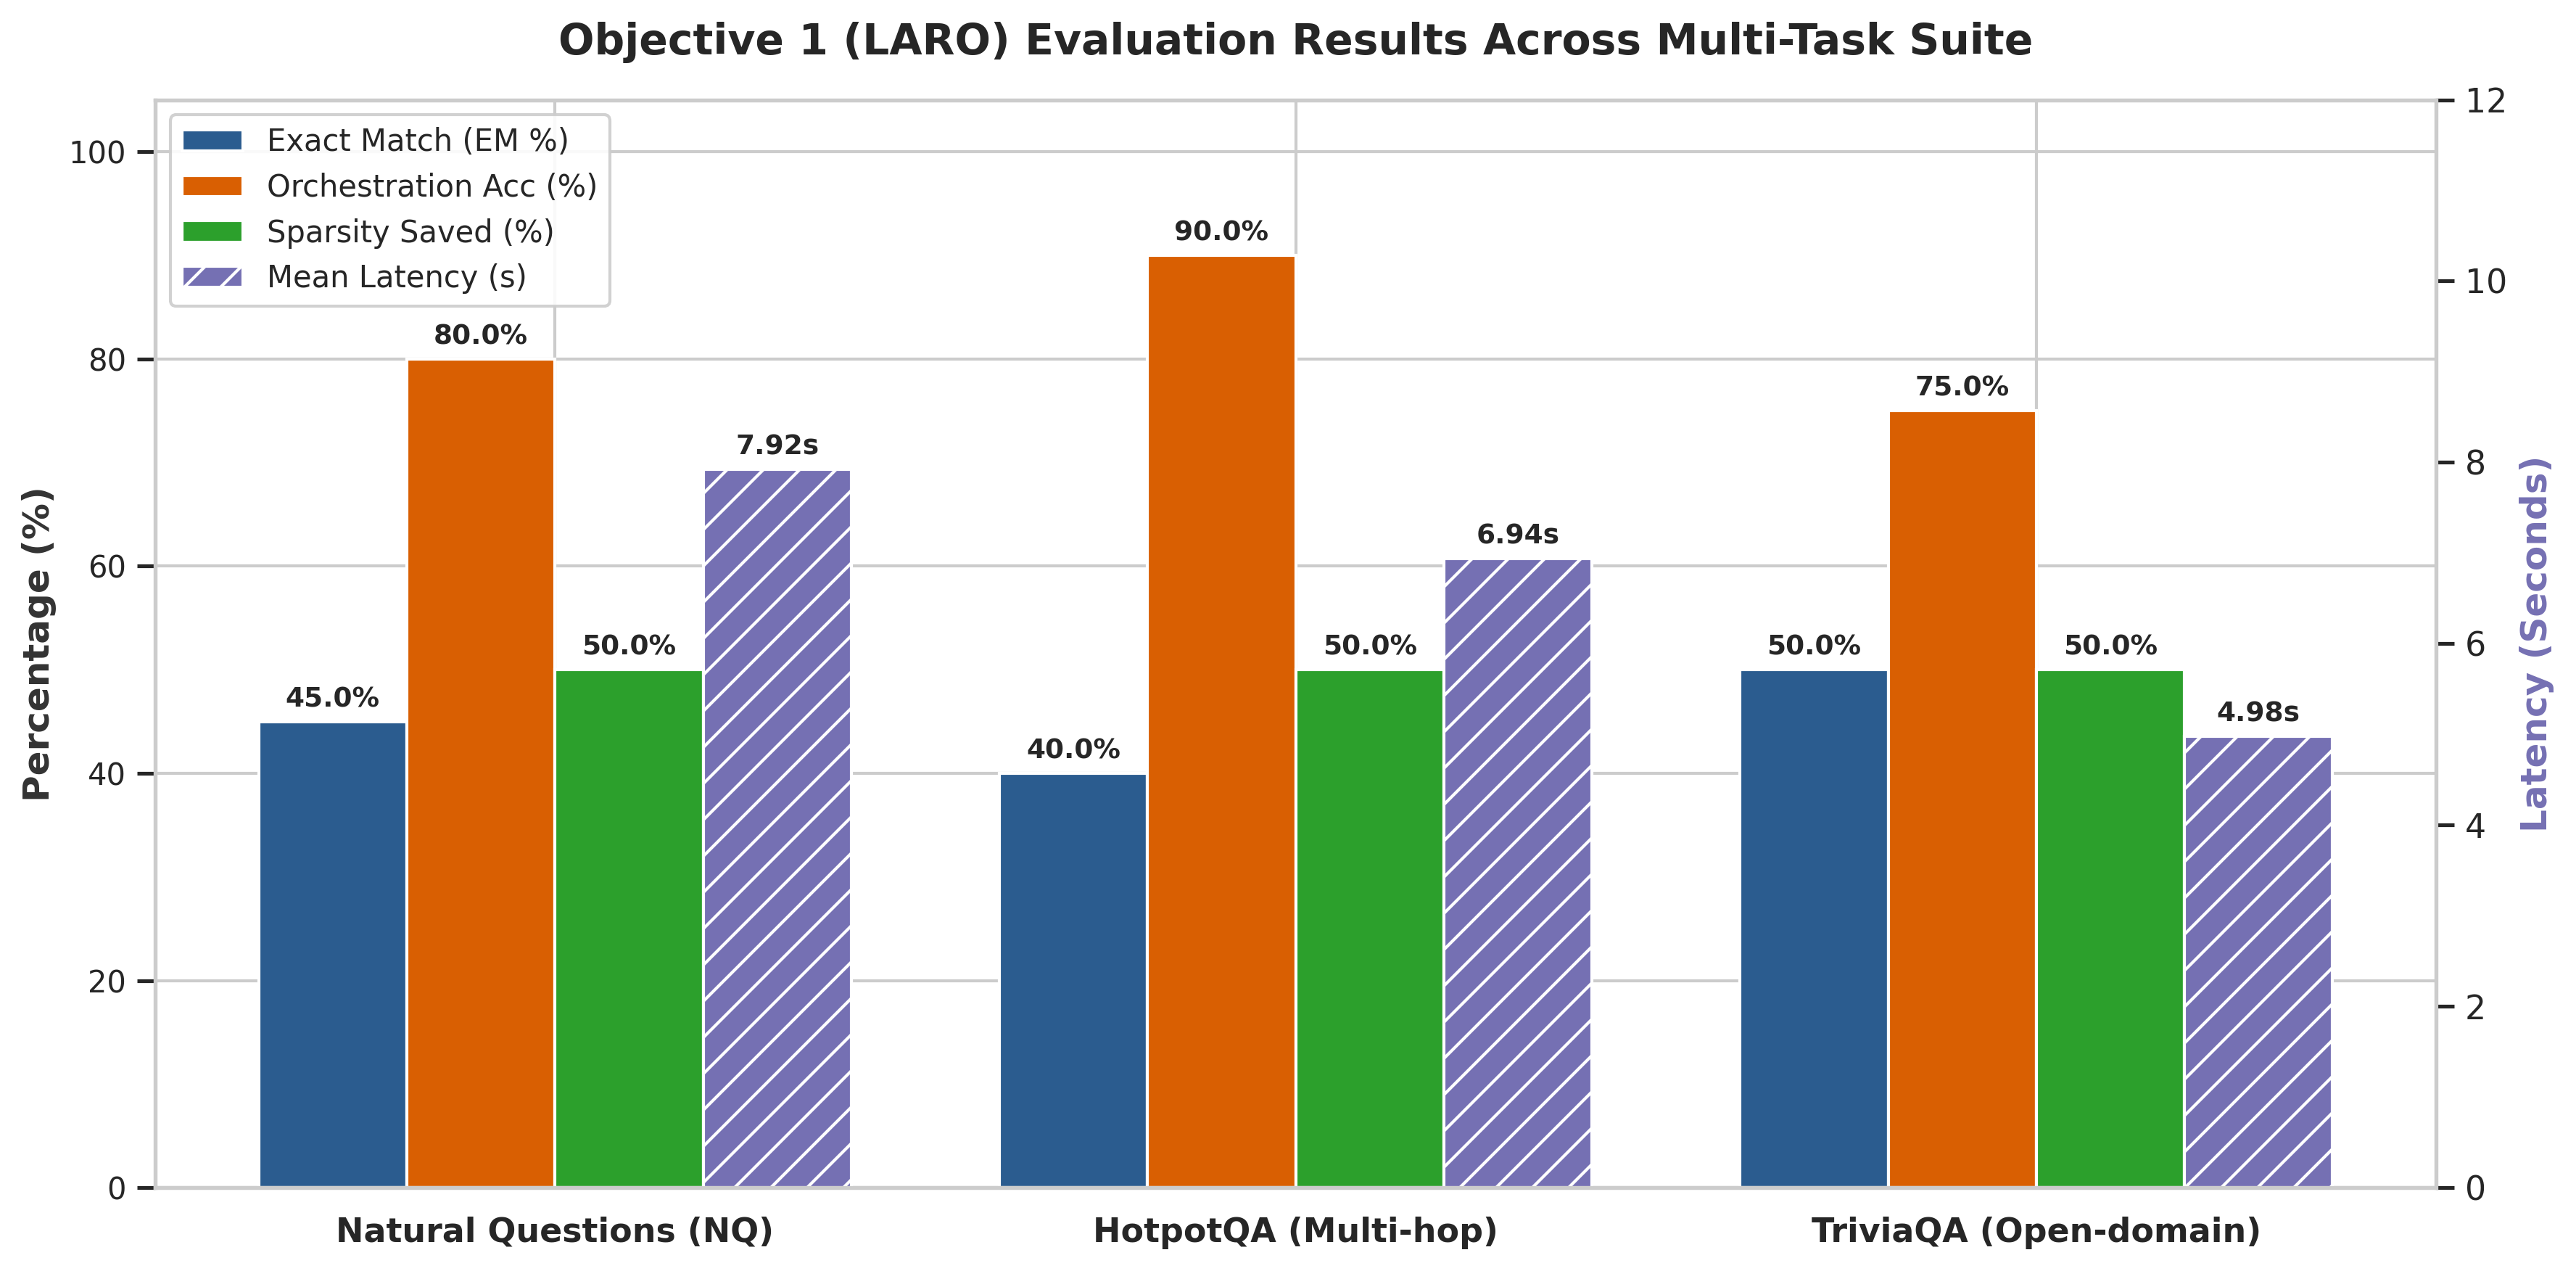

✅ Saved Figure 1 to: /content/drive/My Drive/Objective 1/results/figure1_laro_multitask_results.png


In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set publication-style theme
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.family': 'sans-serif'})

# 1. Dataset Results Data
datasets = ['Natural Questions (NQ)', 'HotpotQA (Multi-hop)', 'TriviaQA (Open-domain)']
exact_match = [45.00, 40.00, 50.00]
orch_accuracy = [80.00, 90.00, 75.00]
sparsity_saved = [50.00, 50.00, 50.00]
latency_sec = [7.92, 6.94, 4.98]

x = np.arange(len(datasets))
width = 0.20  # bar width

# 2. Create Figure with Subplots (Dual-axis for Percentage vs. Latency)
fig, ax1 = plt.subplots(figsize=(12, 6), dpi=300)

# Bars for Percentages (%)
rects1 = ax1.bar(x - width*1.5, exact_match, width, label='Exact Match (EM %)', color='#2b5c8f')
rects2 = ax1.bar(x - width*0.5, orch_accuracy, width, label='Orchestration Acc (%)', color='#d95f02')
rects3 = ax1.bar(x + width*0.5, sparsity_saved, width, label='Sparsity Saved (%)', color='#2ca02c')

# Axis 1 Settings
ax1.set_ylabel('Percentage (%)', fontsize=12, fontweight='bold', color='#333333')
ax1.set_ylim(0, 105)
ax1.set_xticks(x)
ax1.set_xticklabels(datasets, fontsize=11, fontweight='bold')
ax1.tick_params(axis='y', labelsize=10)

# Secondary Axis for Latency (Seconds)
ax2 = ax1.twinx()
rects4 = ax2.bar(x + width*1.5, latency_sec, width, label='Mean Latency (s)', color='#7570b3', hatch='//')
ax2.set_ylabel('Latency (Seconds)', fontsize=12, fontweight='bold', color='#7570b3')
ax2.set_ylim(0, 12)
ax2.grid(False) # Turn off secondary grid lines to avoid clutter

# Title and Legend
plt.title('Objective 1 (LARO) Evaluation Results Across Multi-Task Suite', fontsize=14, fontweight='bold', pad=15)

# Add Values on Top of Bars
def autolabel(rects, ax, is_float=False):
    for rect in rects:
        height = rect.get_height()
        text = f'{height:.2f}s' if is_float else f'{height:.1f}%'
        ax.annotate(text,
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects1, ax1)
autolabel(rects2, ax1)
autolabel(rects3, ax1)
autolabel(rects4, ax2, is_float=True)

# Combine Legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True, framealpha=0.9, fontsize=10)

plt.tight_layout()

# Save High-Res Graph for Thesis
save_path = '/content/drive/My Drive/Objective 1/results/figure1_laro_multitask_results.png'
os.makedirs(os.path.dirname(save_path), exist_ok=True)
plt.savefig(save_path, bbox_inches='tight', dpi=300)
plt.show()
print(f"✅ Saved Figure 1 to: {save_path}")

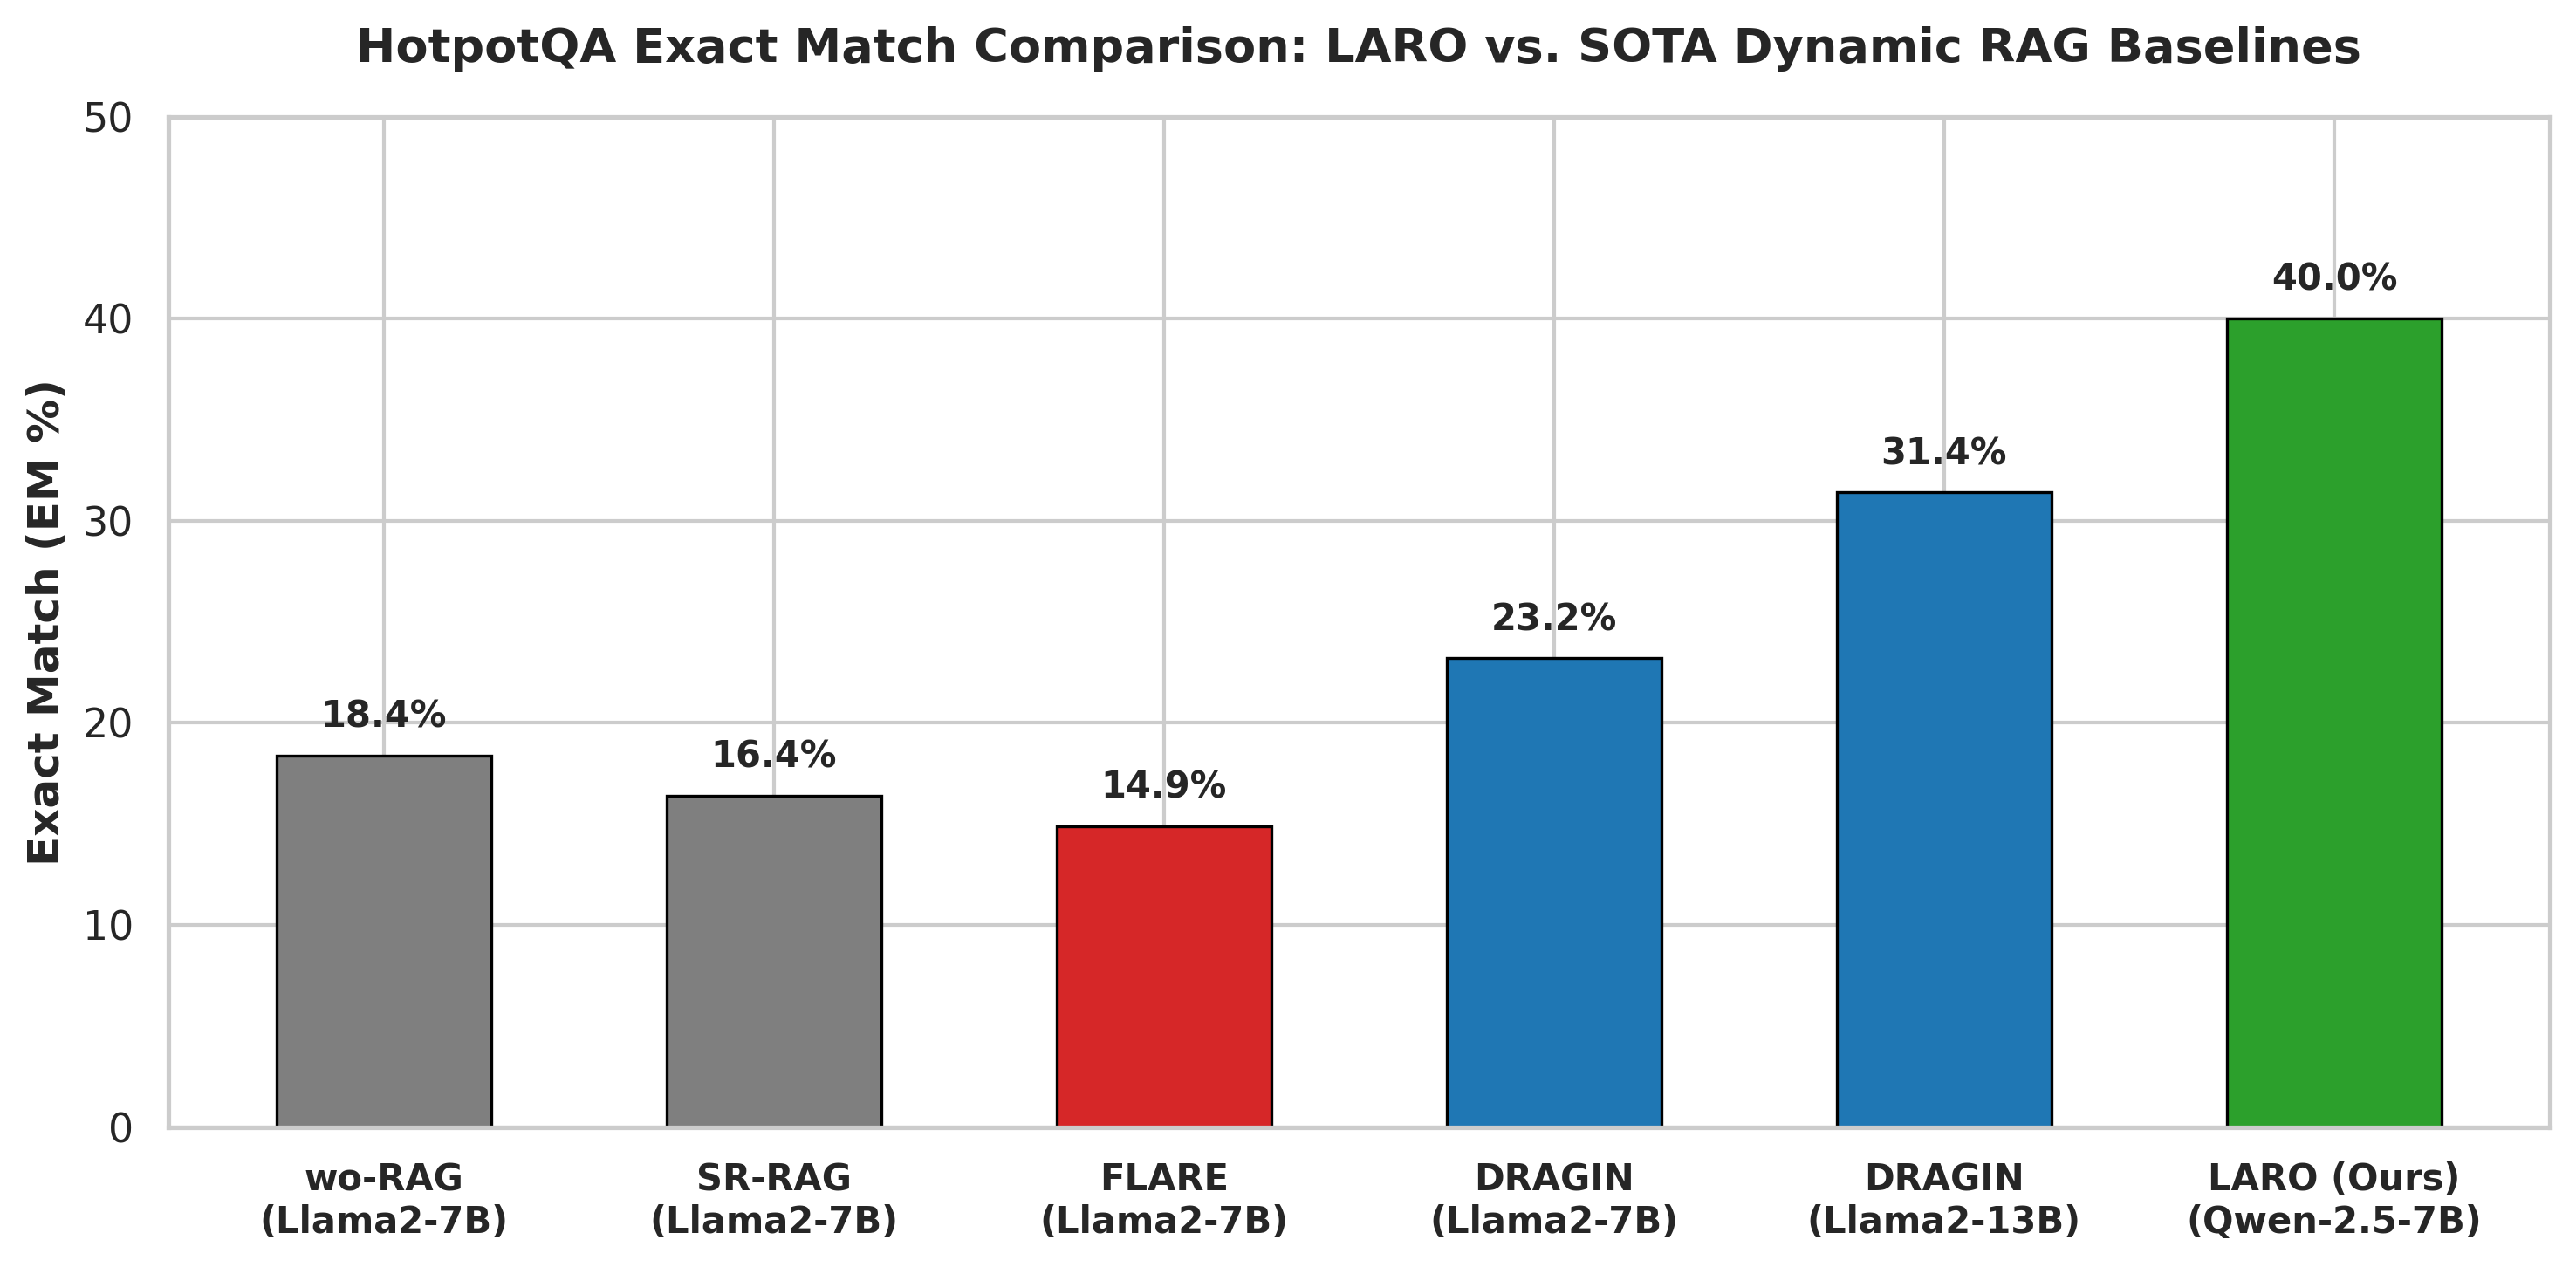

✅ Saved Figure 2 to: /content/drive/My Drive/Objective 1/results/figure2_hotpotqa_baseline_comparison.png


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set publication-style theme
sns.set_theme(style="whitegrid")

# 1. HotpotQA Benchmark Data across Baselines
models = ['wo-RAG\n(Llama2-7B)', 'SR-RAG\n(Llama2-7B)', 'FLARE\n(Llama2-7B)', 'DRAGIN\n(Llama2-7B)', 'DRAGIN\n(Llama2-13B)', 'LARO (Ours)\n(Qwen-2.5-7B)']
em_scores = [18.40, 16.40, 14.90, 23.20, 31.40, 40.00]
colors = ['#7f7f7f', '#7f7f7f', '#d62728', '#1f77b4', '#1f77b4', '#2ca02c'] # Green highlight for LARO

# 2. Create Figure
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
bars = ax.bar(models, em_scores, color=colors, width=0.55, edgecolor='black', linewidth=0.8)

# Axis Settings
ax.set_ylabel('Exact Match (EM %)', fontsize=12, fontweight='bold')
ax.set_ylim(0, 50)
ax.set_title('HotpotQA Exact Match Comparison: LARO vs. SOTA Dynamic RAG Baselines', fontsize=13, fontweight='bold', pad=15)

# Value Labels
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 1.0, f'{yval:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.xticks(fontsize=10, fontweight='bold')
plt.tight_layout()

# Save High-Res Graph for Thesis
save_path2 = '/content/drive/My Drive/Objective 1/results/figure2_hotpotqa_baseline_comparison.png'
plt.savefig(save_path2, bbox_inches='tight', dpi=300)
plt.show()
print(f"✅ Saved Figure 2 to: {save_path2}")